# RQ9 — Functional generalization regimes across biological tasks

## Scientific question

**Do different phage lytic-function prediction tasks occupy distinct generalization regimes, and which combinations of redundancy dependence, homology sensitivity, representation dependence, learner dependence, and evidence support define those regimes?**

RQ9 is a **synthesis RQ**. It does not repeat RQ1–RQ8 independently. Instead, it asks whether the seven frozen supervised tasks show reproducible and biologically interpretable generalization signatures.

### Frozen supervised tasks

**Global lytic recognition**
- `global_easy`
- `global_hard`
- `global_mixed`

**Subtype binary recognition**
- `subtype_endolysin`
- `subtype_depolymerase`
- `subtype_val`

**Clean multiclass discrimination**
- `multiclass_clean`

The task definitions must remain biologically distinct. In particular, other lytic subclasses are not used as negatives in subtype-specific binary tasks, and VAL is retained despite its low positive support under stringent sequence control.

## What RQ9 should establish

For each task, build a compact **generalization fingerprint** from the quantities already shown to matter:

1. overall predictive level;
2. permissive versus strict-corner performance;
3. redundancy sensitivity (`R90→R30`);
4. homology-separation sensitivity (`S90→S30`);
5. extreme `R×S` non-additivity;
6. dependence on representation quality;
7. additional value of ESM2-T30 over T6;
8. dependence on downstream classifier;
9. worst-case performance;
10. evidence support / low-N status where available.

The goal is not to force every task into one mutually exclusive label.  
Instead, RQ9 identifies **multi-axis functional regimes**, e.g. redundancy-sensitive, representation-limited, interaction-driven, classifier-sensitive, robust/separable, or evidence-limited.

## Interpretation guardrails

- Different biological tasks are **not paired experiments** merely because they share proteins.
- Cross-task comparisons are descriptive unless an explicit shared-test design exists.
- Global easy/hard/mixed differ by negative definition and therefore represent different learning problems.
- Binary subtype tasks and multiclass discrimination answer different biological questions.
- VAL remains evidence-limited; large effect sizes must be shown together with absolute support.
- `R×S` effects are native factorial landscape summaries, not exhaustive all-vs-all identity guarantees.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 400)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

TASK_LABEL = {
    "global_easy": "Global easy",
    "global_hard": "Global hard",
    "global_mixed": "Global mixed",
    "subtype_endolysin": "Endolysin",
    "subtype_depolymerase": "Depolymerase",
    "subtype_val": "VAL",
    "multiclass_clean": "Multiclass",
}

BINARY_TASKS = [t for t in TASK_ORDER if t != "multiclass_clean"]

T6 = "esm2_t6_8m"
T30 = "esm2_t30_150m"
ONEHOT = "onehot_1024"

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing Stage12A and Stage12B."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

master = master[master["task"].isin(TASK_ORDER)].copy()

print("Supervised experiment families:", len(master))
print("Tasks:", sorted(master["task"].unique()))
print("Representations:", sorted(master["representation"].unique()))
print("Algorithms:", sorted(master["algorithm"].unique()))

coverage = (
    master.groupby(["task", "R", "S"])
    .size()
    .rename("n_families")
    .reset_index()
)

display(
    coverage.groupby("task")["n_families"]
    .agg(["min", "max", "median"])
    .reindex(TASK_ORDER)
)

Supervised experiment families: 2240
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']


,min,max,median
task,,,
global_easy,20,20,20.0
global_hard,20,20,20.0
global_mixed,20,20,20.0
subtype_endolysin,20,20,20.0
subtype_depolymerase,20,20,20.0
subtype_val,20,20,20.0
multiclass_clean,20,20,20.0


# 1. AP skill and support fields

In [3]:
def detect_prevalence(df):
    for c in [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive_test", "n_outer_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive_test"], errors="coerce")
            / pd.to_numeric(df["n_outer_test"], errors="coerce")
        ), "derived_n_positive_test/n_outer_test"

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_n_positive/n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = pd.to_numeric(df["tp"], errors="coerce") + pd.to_numeric(df["fn"], errors="coerce")
        n = (
            pos
            + pd.to_numeric(df["tn"], errors="coerce")
            + pd.to_numeric(df["fp"], errors="coerce")
        )
        return pos / n, "derived_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

prev, prev_source = detect_prevalence(master)
master["prevalence_for_ap"] = prev

if "ap" in master.columns:
    denom = 1.0 - master["prevalence_for_ap"]
    master["ap_skill"] = np.where(
        denom > 0,
        (master["ap"] - master["prevalence_for_ap"]) / denom,
        np.nan,
    )

print("Prevalence source:", prev_source)

candidate_support_cols = [
    "n_outer_train",
    "n_outer_test",
    "n_positive_train",
    "n_positive_test",
    "n_train",
    "n_test",
    "n_pos_train",
    "n_pos_test",
]

print(
    "Available support columns:",
    [c for c in candidate_support_cols if c in master.columns],
)

Prevalence source: prevalence
Available support columns: []


# 2. Overall performance fingerprints

In [4]:
overall = (
    master.groupby("task")
    .agg(
        n_families=("mcc", "size"),
        mcc_mean=("mcc", "mean"),
        mcc_median=("mcc", "median"),
        mcc_q25=("mcc", lambda x: x.quantile(0.25)),
        mcc_q75=("mcc", lambda x: x.quantile(0.75)),
        mcc_min=("mcc", "min"),
        mcc_max=("mcc", "max"),
    )
    .reindex(TASK_ORDER)
)

display(overall)

,n_families,mcc_mean,mcc_median,mcc_q25,mcc_q75,mcc_min,mcc_max
task,,,,,,,
global_easy,320,0.687194,0.715267,0.530544,0.866558,0.111129,0.963380
global_hard,320,0.869307,0.896734,0.816014,0.934187,0.666141,0.964477
global_mixed,320,0.682930,0.721355,0.533349,0.864702,0.098878,0.963493
subtype_endolysin,320,0.655059,0.697403,0.491860,0.856708,0.000000,0.962785
subtype_depolymerase,320,0.771119,0.840849,0.733122,0.900751,0.000000,0.962101
subtype_val,320,0.448936,0.483795,0.149062,0.719331,0.000000,0.926850
multiclass_clean,320,0.776218,0.811130,0.692556,0.860198,0.474300,0.932059


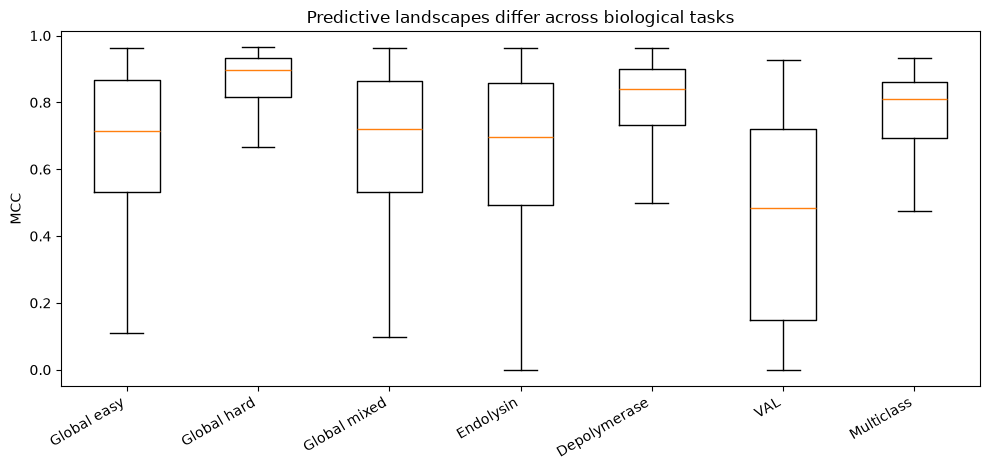

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.8))
data = [
    master.loc[master["task"].eq(t), "mcc"].dropna().to_numpy()
    for t in TASK_ORDER
]
ax.boxplot(
    data,
    tick_labels=[TASK_LABEL[t] for t in TASK_ORDER],
    showfliers=False,
)
ax.set_ylabel("MCC")
ax.set_title("Predictive landscapes differ across biological tasks")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Raw cross-task MCC is descriptive because class prevalence, negative definition, and biological discrimination target differ across tasks. The important RQ9 signal is the **shape of each task's generalization landscape**, not only its absolute score.

# 3. Permissive and strict corners

In [6]:
corner_rows = []

for task in TASK_ORDER:
    for r, s, name in [
        (90, 90, "R90_S90"),
        (30, 30, "R30_S30"),
    ]:
        g = master[
            master["task"].eq(task)
            & master["R"].eq(r)
            & master["S"].eq(s)
        ]

        corner_rows.append(
            {
                "task": task,
                "corner": name,
                "n": len(g),
                "mcc_mean": g["mcc"].mean(),
                "mcc_median": g["mcc"].median(),
                "mcc_q25": g["mcc"].quantile(0.25),
                "mcc_q75": g["mcc"].quantile(0.75),
            }
        )

corners = pd.DataFrame(corner_rows)

display(
    corners.pivot(
        index="task",
        columns="corner",
        values="mcc_median",
    ).reindex(TASK_ORDER)
)

corner_wide = corners.pivot(
    index="task",
    columns="corner",
    values="mcc_median",
)

corner_wide["strict_minus_permissive"] = (
    corner_wide["R30_S30"] - corner_wide["R90_S90"]
)

display(corner_wide.reindex(TASK_ORDER))

corner,R30_S30,R90_S90
task,,
global_easy,0.664537,0.774564
global_hard,0.873673,0.939674
global_mixed,0.648663,0.783495
subtype_endolysin,0.590197,0.774572
subtype_depolymerase,0.849102,0.868501
subtype_val,0.406358,0.714356
multiclass_clean,0.820753,0.840622


corner,R30_S30,R90_S90,strict_minus_permissive
task,,,
global_easy,0.664537,0.774564,-0.110027
global_hard,0.873673,0.939674,-0.066001
global_mixed,0.648663,0.783495,-0.134832
subtype_endolysin,0.590197,0.774572,-0.184375
subtype_depolymerase,0.849102,0.868501,-0.019399
subtype_val,0.406358,0.714356,-0.307998
multiclass_clean,0.820753,0.840622,-0.019869


# 4. Redundancy sensitivity by task

In [7]:
r_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "S"]
):
    task, rep, alg, s = keys
    lookup = dict(zip(grp["R"].astype(int), grp["mcc"]))

    if 90 in lookup and 30 in lookup:
        r_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "S": int(s),
                "delta_R30_minus_R90": lookup[30] - lookup[90],
            }
        )

r_effects = pd.DataFrame(r_rows)

r_task = (
    r_effects.groupby("task")[
        "delta_R30_minus_R90"
    ]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
        min="min",
        max="max",
    )
    .reindex(TASK_ORDER)
)

display(r_task)

,n,mean,median,median_abs,fraction_negative,min,max
task,,,,,,,
global_easy,80,-0.112667,-0.102103,0.102103,1.0000,-0.372241,-0.020104
global_hard,80,-0.053908,-0.045614,0.045614,0.9875,-0.154351,0.011016
global_mixed,80,-0.117770,-0.103402,0.103402,1.0000,-0.350685,-0.025496
subtype_endolysin,80,-0.161694,-0.142878,0.142878,1.0000,-0.513991,-0.062069
subtype_depolymerase,80,0.024989,0.018144,0.037814,0.3750,-0.092780,0.182626
subtype_val,80,-0.067767,-0.044254,0.111745,0.5875,-0.497191,0.514487
multiclass_clean,80,-0.023381,-0.022622,0.030760,0.8000,-0.138367,0.136891


# 5. Homology-separation sensitivity by task

In [8]:
s_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "R"]
):
    task, rep, alg, r = keys
    lookup = dict(zip(grp["S"].astype(int), grp["mcc"]))

    if 90 in lookup and 30 in lookup:
        s_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "R": int(r),
                "delta_S30_minus_S90": lookup[30] - lookup[90],
            }
        )

s_effects = pd.DataFrame(s_rows)

s_task = (
    s_effects.groupby("task")[
        "delta_S30_minus_S90"
    ]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
        min="min",
        max="max",
    )
    .reindex(TASK_ORDER)
)

display(s_task)

,n,mean,median,median_abs,fraction_negative,min,max
task,,,,,,,
global_easy,80,-0.033751,-0.017895,0.018622,0.7750,-0.291342,0.026300
global_hard,80,-0.009150,-0.007104,0.012490,0.6750,-0.113485,0.039707
global_mixed,80,-0.036990,-0.023472,0.023472,0.8500,-0.250811,0.019251
subtype_endolysin,80,-0.031038,-0.019415,0.027656,0.7000,-0.309527,0.065058
subtype_depolymerase,80,-0.012164,-0.007922,0.021504,0.6125,-0.119394,0.128736
subtype_val,80,-0.122407,-0.035334,0.077636,0.5500,-0.693917,0.254274
multiclass_clean,80,-0.025357,-0.019777,0.025002,0.8000,-0.120168,0.060397


# 6. Extreme R×S interaction by task

In [9]:
interaction_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    lookup = {
        (int(r), int(s)): mcc
        for r, s, mcc in zip(
            grp["R"],
            grp["S"],
            grp["mcc"],
        )
    }

    needed = [(90, 90), (90, 30), (30, 90), (30, 30)]

    if all(k in lookup for k in needed):
        # I = ΔS|R30 - ΔS|R90
        interaction = (
            (lookup[(30, 30)] - lookup[(30, 90)])
            - (lookup[(90, 30)] - lookup[(90, 90)])
        )

        interaction_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "interaction_extreme": interaction,
            }
        )

interactions = pd.DataFrame(interaction_rows)

interaction_task = (
    interactions.groupby("task")[
        "interaction_extreme"
    ]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_positive=lambda x: (x > 0).mean(),
        min="min",
        max="max",
    )
    .reindex(TASK_ORDER)
)

display(interaction_task)

,n,mean,median,median_abs,fraction_positive,min,max
task,,,,,,,
global_easy,20,0.068535,0.047088,0.047088,0.95,-0.014544,0.249226
global_hard,20,0.026313,0.021067,0.022814,0.80,-0.032326,0.112449
global_mixed,20,0.039235,0.010090,0.017270,0.70,-0.043694,0.210352
subtype_endolysin,20,0.094910,0.080343,0.080343,0.95,-0.040897,0.329699
subtype_depolymerase,20,0.058496,0.061084,0.061084,0.90,-0.015904,0.180169
subtype_val,20,0.354234,0.339206,0.339206,1.00,0.054128,0.661494
multiclass_clean,20,0.031212,0.028747,0.029222,0.90,-0.032466,0.097878


Positive extreme interaction means that the joint strict `R30/S30` condition is **less detrimental than expected from simply adding the isolated R and S penalties**. This is predictive non-additivity, not biological synergy.

# 7. Representation dependence by task

In [10]:
rep_spread_rows = []

for keys, grp in master.groupby(
    ["task", "R", "S", "algorithm"]
):
    task, r, s, alg = keys
    vals = grp["mcc"].dropna()

    if len(vals) >= 2:
        rep_spread_rows.append(
            {
                "task": task,
                "R": int(r),
                "S": int(s),
                "algorithm": alg,
                "representation_range": vals.max() - vals.min(),
                "representation_std": vals.std(ddof=0),
            }
        )

rep_spread = pd.DataFrame(rep_spread_rows)

rep_task = (
    rep_spread.groupby("task")
    .agg(
        median_representation_range=(
            "representation_range",
            "median",
        ),
        mean_representation_range=(
            "representation_range",
            "mean",
        ),
        median_representation_std=(
            "representation_std",
            "median",
        ),
    )
    .reindex(TASK_ORDER)
)

display(rep_task)

,median_representation_range,mean_representation_range,median_representation_std
task,,,
global_easy,0.469211,0.492523,0.179439
global_hard,0.170932,0.170872,0.068514
global_mixed,0.477438,0.493035,0.182779
subtype_endolysin,0.510824,0.534725,0.199785
subtype_depolymerase,0.315777,0.403462,0.123243
subtype_val,0.706560,0.676260,0.276864
multiclass_clean,0.240024,0.248036,0.094734


# 8. T30 capacity gain by task

In [11]:
t30_t6_rows = []

for keys, grp in master.groupby(
    ["task", "R", "S", "algorithm"]
):
    task, r, s, alg = keys
    lookup = dict(zip(grp["representation"], grp["mcc"]))

    if T6 in lookup and T30 in lookup:
        t30_t6_rows.append(
            {
                "task": task,
                "R": int(r),
                "S": int(s),
                "algorithm": alg,
                "delta_T30_minus_T6": lookup[T30] - lookup[T6],
            }
        )

t30_t6 = pd.DataFrame(t30_t6_rows)

capacity_task = (
    t30_t6.groupby("task")[
        "delta_T30_minus_T6"
    ]
    .agg(
        n="size",
        mean="mean",
        median="median",
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_gt_005=lambda x: (x > 0.05).mean(),
        fraction_equivalent=lambda x: (x.abs() <= 0.01).mean(),
    )
    .reindex(TASK_ORDER)
)

display(capacity_task)

,n,mean,median,fraction_positive,fraction_gt_005,fraction_equivalent
task,,,,,,
global_easy,80,0.113703,0.113017,1.0000,1.0000,0.0000
global_hard,80,0.007452,0.007816,0.8000,0.0000,0.5625
global_mixed,80,0.113086,0.104026,1.0000,1.0000,0.0000
subtype_endolysin,80,0.132807,0.133600,1.0000,0.9875,0.0000
subtype_depolymerase,80,0.028987,0.021048,0.8375,0.2250,0.2750
subtype_val,80,0.164512,0.121127,0.9375,0.8875,0.0375
multiclass_clean,80,0.031465,0.030146,0.9250,0.2250,0.1875


# 9. T30 versus one-hot representation lift

In [12]:
t30_onehot_rows = []

for keys, grp in master.groupby(
    ["task", "R", "S", "algorithm"]
):
    task, r, s, alg = keys
    lookup = dict(zip(grp["representation"], grp["mcc"]))

    if ONEHOT in lookup and T30 in lookup:
        t30_onehot_rows.append(
            {
                "task": task,
                "R": int(r),
                "S": int(s),
                "algorithm": alg,
                "delta_T30_minus_onehot": lookup[T30] - lookup[ONEHOT],
            }
        )

t30_onehot = pd.DataFrame(t30_onehot_rows)

t30_onehot_task = (
    t30_onehot.groupby("task")[
        "delta_T30_minus_onehot"
    ]
    .agg(
        n="size",
        mean="mean",
        median="median",
        fraction_positive=lambda x: (x > 0).mean(),
    )
    .reindex(TASK_ORDER)
)

display(t30_onehot_task)

,n,mean,median,fraction_positive
task,,,,
global_easy,80,0.489926,0.469211,1.0
global_hard,80,0.169416,0.170932,1.0
global_mixed,80,0.491618,0.477438,1.0
subtype_endolysin,80,0.533461,0.510824,1.0
subtype_depolymerase,80,0.358541,0.268255,1.0
subtype_val,80,0.662395,0.685345,1.0
multiclass_clean,80,0.230462,0.222679,1.0


# 10. Algorithm dependence by task

In [13]:
alg_spread_rows = []

for keys, grp in master.groupby(
    ["task", "R", "S", "representation"]
):
    task, r, s, rep = keys
    vals = grp["mcc"].dropna()

    if len(vals) >= 2:
        alg_spread_rows.append(
            {
                "task": task,
                "R": int(r),
                "S": int(s),
                "representation": rep,
                "algorithm_range": vals.max() - vals.min(),
                "algorithm_std": vals.std(ddof=0),
            }
        )

alg_spread = pd.DataFrame(alg_spread_rows)

alg_task = (
    alg_spread.groupby("task")
    .agg(
        median_algorithm_range=("algorithm_range", "median"),
        mean_algorithm_range=("algorithm_range", "mean"),
        median_algorithm_std=("algorithm_std", "median"),
    )
    .reindex(TASK_ORDER)
)

display(alg_task)

,median_algorithm_range,mean_algorithm_range,median_algorithm_std
task,,,
global_easy,0.130938,0.178860,0.048877
global_hard,0.032686,0.044123,0.011830
global_mixed,0.163594,0.193351,0.058286
subtype_endolysin,0.171483,0.200748,0.063379
subtype_depolymerase,0.194434,0.291996,0.071373
subtype_val,0.322258,0.328144,0.116323
multiclass_clean,0.082071,0.106214,0.030198


# 11. Representation dependence versus classifier dependence by task

In [14]:
factor_dependence = (
    rep_task[
        ["median_representation_range"]
    ]
    .join(
        alg_task[
            ["median_algorithm_range"]
        ],
        how="outer",
    )
)

factor_dependence["rep_to_alg_range_ratio"] = (
    factor_dependence["median_representation_range"]
    / factor_dependence["median_algorithm_range"]
)

display(factor_dependence.reindex(TASK_ORDER))

,median_representation_range,median_algorithm_range,rep_to_alg_range_ratio
task,,,
global_easy,0.469211,0.130938,3.583470
global_hard,0.170932,0.032686,5.229462
global_mixed,0.477438,0.163594,2.918431
subtype_endolysin,0.510824,0.171483,2.978860
subtype_depolymerase,0.315777,0.194434,1.624084
subtype_val,0.706560,0.322258,2.192530
multiclass_clean,0.240024,0.082071,2.924588


This ratio is descriptive. Values above 1 indicate that changing the protein representation moves MCC more than changing the downstream classifier within the same task.

# 12. Worst-case generalization by task

In [15]:
surface_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    if len(grp) != 16:
        continue

    surface_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "worst_mcc": grp["mcc"].min(),
            "median_mcc": grp["mcc"].median(),
            "best_mcc": grp["mcc"].max(),
            "surface_range": grp["mcc"].max() - grp["mcc"].min(),
        }
    )

surfaces = pd.DataFrame(surface_rows)

surface_task = (
    surfaces.groupby("task")
    .agg(
        median_worst_mcc=("worst_mcc", "median"),
        median_surface_mcc=("median_mcc", "median"),
        median_surface_range=("surface_range", "median"),
        max_surface_range=("surface_range", "max"),
    )
    .reindex(TASK_ORDER)
)

display(surface_task)

,median_worst_mcc,median_surface_mcc,median_surface_range,max_surface_range
task,,,,
global_easy,0.636519,0.706358,0.146083,0.396917
global_hard,0.846195,0.900984,0.074794,0.181150
global_mixed,0.643778,0.695914,0.142115,0.356277
subtype_endolysin,0.555640,0.668854,0.197765,0.543993
subtype_depolymerase,0.792688,0.834868,0.088956,0.189463
subtype_val,0.193064,0.457195,0.447140,0.702867
multiclass_clean,0.741285,0.805212,0.117816,0.188879


# 13. Evidence support and low-N diagnostics

In [16]:
def choose_first_existing(columns):
    for c in columns:
        if c in master.columns:
            return c
    return None

ntrain_col = choose_first_existing(
    ["n_outer_train", "n_train", "n_training"]
)
ntest_col = choose_first_existing(
    ["n_outer_test", "n_test"]
)
npos_train_col = choose_first_existing(
    ["n_positive_train", "n_pos_train", "positive_train_count"]
)
npos_test_col = choose_first_existing(
    ["n_positive_test", "n_pos_test", "positive_test_count"]
)

support_info = pd.DataFrame(index=TASK_ORDER)

for col, out_name in [
    (ntrain_col, "median_n_train"),
    (ntest_col, "median_n_test"),
    (npos_train_col, "median_positive_train"),
    (npos_test_col, "median_positive_test"),
]:
    if col is not None:
        support_info[out_name] = (
            master.groupby("task")[col]
            .median()
            .reindex(TASK_ORDER)
        )

# Strict-corner support is often more informative.
strict_master = master[
    master["R"].eq(30)
    & master["S"].eq(30)
]

for col, out_name in [
    (ntrain_col, "strict_n_train"),
    (ntest_col, "strict_n_test"),
    (npos_train_col, "strict_positive_train"),
    (npos_test_col, "strict_positive_test"),
]:
    if col is not None:
        support_info[out_name] = (
            strict_master.groupby("task")[col]
            .median()
            .reindex(TASK_ORDER)
        )

display(support_info)

""
global_easy
global_hard
global_mixed
subtype_endolysin
subtype_depolymerase
subtype_val
multiclass_clean


For multiclass, a single `n_positive_test` field may not capture class-specific VAL support. If per-class support is not present in the master table, multiclass VAL support must remain a known external caveat from the split manifests and dedicated low-N analysis.

# 14. Build the task-level generalization fingerprint

In [17]:
fingerprint = pd.DataFrame(index=TASK_ORDER)

fingerprint["overall_mcc"] = overall["mcc_median"]
fingerprint["permissive_mcc"] = corner_wide["R90_S90"]
fingerprint["strict_mcc"] = corner_wide["R30_S30"]
fingerprint["strict_minus_permissive"] = corner_wide["strict_minus_permissive"]

fingerprint["R_signed"] = r_task["median"]
fingerprint["R_abs"] = r_task["median_abs"]

fingerprint["S_signed"] = s_task["median"]
fingerprint["S_abs"] = s_task["median_abs"]

fingerprint["RxS_interaction"] = interaction_task["median"]
fingerprint["RxS_abs"] = interaction_task["median_abs"]

fingerprint["representation_range"] = rep_task["median_representation_range"]
fingerprint["T30_minus_T6"] = capacity_task["median"]
fingerprint["T30_minus_onehot"] = t30_onehot_task["median"]

fingerprint["algorithm_range"] = alg_task["median_algorithm_range"]
fingerprint["rep_to_alg_ratio"] = factor_dependence["rep_to_alg_range_ratio"]

fingerprint["worst_mcc"] = surface_task["median_worst_mcc"]
fingerprint["surface_range"] = surface_task["median_surface_range"]

for c in support_info.columns:
    fingerprint[c] = support_info[c]

display(fingerprint)

,overall_mcc,permissive_mcc,strict_mcc,strict_minus_permissive,R_signed,R_abs,S_signed,S_abs,RxS_interaction,RxS_abs,representation_range,T30_minus_T6,T30_minus_onehot,algorithm_range,rep_to_alg_ratio,worst_mcc,surface_range
global_easy,0.715267,0.774564,0.664537,-0.110027,-0.102103,0.102103,-0.017895,0.018622,0.047088,0.047088,0.469211,0.113017,0.469211,0.130938,3.583470,0.636519,0.146083
global_hard,0.896734,0.939674,0.873673,-0.066001,-0.045614,0.045614,-0.007104,0.012490,0.021067,0.022814,0.170932,0.007816,0.170932,0.032686,5.229462,0.846195,0.074794
global_mixed,0.721355,0.783495,0.648663,-0.134832,-0.103402,0.103402,-0.023472,0.023472,0.010090,0.017270,0.477438,0.104026,0.477438,0.163594,2.918431,0.643778,0.142115
subtype_endolysin,0.697403,0.774572,0.590197,-0.184375,-0.142878,0.142878,-0.019415,0.027656,0.080343,0.080343,0.510824,0.133600,0.510824,0.171483,2.978860,0.555640,0.197765
subtype_depolymerase,0.840849,0.868501,0.849102,-0.019399,0.018144,0.037814,-0.007922,0.021504,0.061084,0.061084,0.315777,0.021048,0.268255,0.194434,1.624084,0.792688,0.088956
subtype_val,0.483795,0.714356,0.406358,-0.307998,-0.044254,0.111745,-0.035334,0.077636,0.339206,0.339206,0.706560,0.121127,0.685345,0.322258,2.192530,0.193064,0.447140
multiclass_clean,0.811130,0.840622,0.820753,-0.019869,-0.022622,0.030760,-0.019777,0.025002,0.028747,0.029222,0.240024,0.030146,0.222679,0.082071,2.924588,0.741285,0.117816


# 15. Standardized task fingerprint heatmap

,overall_mcc,strict_mcc,R_abs,S_abs,RxS_abs,T30_minus_T6,T30_minus_onehot,algorithm_range,worst_mcc,surface_range
global_easy,-0.183474,-0.185373,0.498021,-0.538396,-0.361392,0.748519,0.399787,-0.303622,0.033054,-0.232876
global_hard,1.276225,1.161239,-0.904553,-0.842376,-0.591031,-1.368784,-1.339989,-1.457960,1.077216,-0.837870
global_mixed,-0.134503,-0.287580,0.530265,-0.297968,-0.643481,0.567564,0.447768,0.080050,0.069205,-0.266552
subtype_endolysin,-0.327169,-0.664039,1.510404,-0.090569,-0.046792,1.162788,0.642498,0.172735,-0.369714,0.205718
subtype_depolymerase,0.826695,1.003027,-1.098200,-0.395534,-0.228987,-1.102468,-0.772332,0.442385,0.810761,-0.717683
subtype_val,-2.045412,-1.847767,0.737417,2.386995,2.402093,0.911745,1.660429,1.944163,-2.175299,2.322025
multiclass_clean,0.587638,0.820493,-1.273353,-0.222152,-0.530410,-0.919364,-1.038161,-0.877750,0.554776,-0.472761


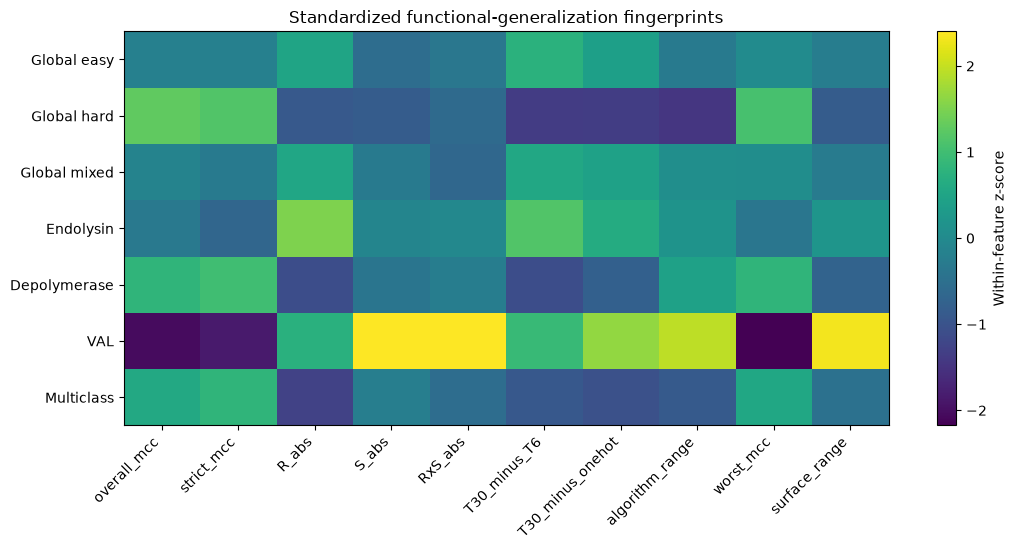

In [18]:
heatmap_cols = [
    "overall_mcc",
    "strict_mcc",
    "R_abs",
    "S_abs",
    "RxS_abs",
    "T30_minus_T6",
    "T30_minus_onehot",
    "algorithm_range",
    "worst_mcc",
    "surface_range",
]

heat = fingerprint[heatmap_cols].copy()

# Standardize column-wise only when variation exists.
heat_z = heat.copy()
for c in heat.columns:
    sd = heat[c].std(ddof=0)
    if pd.notna(sd) and sd > 0:
        heat_z[c] = (heat[c] - heat[c].mean()) / sd
    else:
        heat_z[c] = 0.0

display(heat_z)

fig, ax = plt.subplots(figsize=(11, 5.6))
im = ax.imshow(heat_z.to_numpy(), aspect="auto")

ax.set_xticks(
    range(len(heatmap_cols)),
    heatmap_cols,
    rotation=45,
    ha="right",
)
ax.set_yticks(
    range(len(TASK_ORDER)),
    [TASK_LABEL[t] for t in TASK_ORDER],
)
ax.set_title("Standardized functional-generalization fingerprints")
plt.colorbar(im, ax=ax, label="Within-feature z-score")
plt.tight_layout()
plt.show()

The heatmap is a compact visual summary only. It does not imply that all fingerprint dimensions are statistically independent or equally important.

# 16. Similarity between task fingerprints

In [19]:
# Use a compact set of finite landscape-shape descriptors.
sim_cols = [
    "R_abs",
    "S_abs",
    "RxS_abs",
    "T30_minus_T6",
    "T30_minus_onehot",
    "algorithm_range",
    "surface_range",
]

X = fingerprint[sim_cols].copy()

for c in X.columns:
    sd = X[c].std(ddof=0)
    if pd.notna(sd) and sd > 0:
        X[c] = (X[c] - X[c].mean()) / sd
    else:
        X[c] = 0.0

# Euclidean distance in standardized fingerprint space.
dist = pd.DataFrame(
    np.nan,
    index=TASK_ORDER,
    columns=TASK_ORDER,
)

for t1 in TASK_ORDER:
    for t2 in TASK_ORDER:
        a = X.loc[t1].to_numpy(dtype=float)
        b = X.loc[t2].to_numpy(dtype=float)
        mask = np.isfinite(a) & np.isfinite(b)
        if mask.any():
            dist.loc[t1, t2] = np.sqrt(np.sum((a[mask] - b[mask]) ** 2))

display(dist)

,global_easy,global_hard,global_mixed,subtype_endolysin,subtype_depolymerase,subtype_val,multiclass_clean
global_easy,0.000000,3.364620,0.567278,1.405080,2.859623,5.426600,2.915998
global_hard,3.364620,0.000000,3.463414,4.558595,2.094554,7.605682,1.134634
global_mixed,0.567278,3.463414,0.000000,1.408391,2.728678,5.319033,2.941159
subtype_endolysin,1.405080,4.558595,1.408391,0.000000,3.871631,4.631283,4.089539
subtype_depolymerase,2.859623,2.094554,2.728678,3.871631,0.000000,6.285307,1.434758
subtype_val,5.426600,7.605682,5.319033,4.631283,6.285307,0.000000,6.771986
multiclass_clean,2.915998,1.134634,2.941159,4.089539,1.434758,6.771986,0.000000


In [20]:
nearest_rows = []

for task in TASK_ORDER:
    s = dist.loc[task].drop(index=task).sort_values()
    nearest_rows.append(
        {
            "task": task,
            "nearest_task": s.index[0],
            "distance": s.iloc[0],
        }
    )

nearest = pd.DataFrame(nearest_rows)
display(nearest)

,task,nearest_task,distance
0,global_easy,global_mixed,0.567278
1,global_hard,multiclass_clean,1.134634
2,global_mixed,global_easy,0.567278
3,subtype_endolysin,global_easy,1.405080
4,subtype_depolymerase,multiclass_clean,1.434758
5,subtype_val,subtype_endolysin,4.631283
6,multiclass_clean,global_hard,1.134634


Task-fingerprint distance is exploratory and descriptive. It is useful for identifying whether, for example, global easy and global mixed occupy similar landscapes, but it is not a formal clustering result.

# 17. Multi-axis regime flags

In [21]:
# Transparent descriptive thresholds chosen to identify pronounced effects.
# They are not statistical significance thresholds.
THRESHOLDS = {
    "R_sensitive": 0.08,
    "S_sensitive": 0.03,
    "interaction_driven": 0.05,
    "capacity_sensitive": 0.05,
    "representation_sensitive": 0.20,
    "classifier_sensitive": 0.15,
    "high_worst_case": 0.75,
}

regimes = pd.DataFrame(index=TASK_ORDER)

regimes["redundancy_sensitive"] = (
    fingerprint["R_abs"] >= THRESHOLDS["R_sensitive"]
)

regimes["homology_sensitive"] = (
    fingerprint["S_abs"] >= THRESHOLDS["S_sensitive"]
)

regimes["interaction_driven"] = (
    fingerprint["RxS_abs"] >= THRESHOLDS["interaction_driven"]
)

regimes["capacity_sensitive"] = (
    fingerprint["T30_minus_T6"] >= THRESHOLDS["capacity_sensitive"]
)

regimes["representation_sensitive"] = (
    fingerprint["T30_minus_onehot"] >= THRESHOLDS["representation_sensitive"]
)

regimes["classifier_sensitive"] = (
    fingerprint["algorithm_range"] >= THRESHOLDS["classifier_sensitive"]
)

regimes["high_worst_case"] = (
    fingerprint["worst_mcc"] >= THRESHOLDS["high_worst_case"]
)

# Evidence-limited is explicitly biological/support-based.
regimes["evidence_limited"] = False
if "strict_positive_test" in fingerprint.columns:
    regimes["evidence_limited"] = (
        fingerprint["strict_positive_test"] < 50
    ).fillna(False)

# VAL is known a priori to be low-N in the frozen design even if the
# master table does not expose the support field.
if "subtype_val" in regimes.index:
    regimes.loc["subtype_val", "evidence_limited"] = True

display(regimes)

,redundancy_sensitive,homology_sensitive,interaction_driven,capacity_sensitive,representation_sensitive,classifier_sensitive,high_worst_case,evidence_limited
global_easy,True,False,False,True,True,False,False,False
global_hard,False,False,False,False,False,False,True,False
global_mixed,True,False,False,True,True,True,False,False
subtype_endolysin,True,False,True,True,True,True,False,False
subtype_depolymerase,False,False,True,False,True,True,True,False
subtype_val,True,True,True,True,True,True,False,True
multiclass_clean,False,False,False,False,True,False,False,False


# 18. Compact textual regime labels

In [22]:
def regime_label(task):
    flags = []

    row = regimes.loc[task]

    if row["evidence_limited"]:
        flags.append("evidence-limited")
    if row["high_worst_case"]:
        flags.append("high-floor")
    if row["redundancy_sensitive"]:
        flags.append("R-sensitive")
    if row["homology_sensitive"]:
        flags.append("S-sensitive")
    if row["interaction_driven"]:
        flags.append("interaction-driven")
    if row["capacity_sensitive"]:
        flags.append("capacity-sensitive")
    if row["representation_sensitive"]:
        flags.append("representation-sensitive")
    if row["classifier_sensitive"]:
        flags.append("classifier-sensitive")

    return ", ".join(flags) if flags else "comparatively stable"

regime_summary = pd.DataFrame(
    {
        "task": TASK_ORDER,
        "task_label": [TASK_LABEL[t] for t in TASK_ORDER],
        "regime_signature": [regime_label(t) for t in TASK_ORDER],
    }
)

display(regime_summary)

,task,task_label,regime_signature
0,global_easy,Global easy,"R-sensitive, capacity-sensitive, representatio..."
1,global_hard,Global hard,high-floor
2,global_mixed,Global mixed,"R-sensitive, capacity-sensitive, representatio..."
3,subtype_endolysin,Endolysin,"R-sensitive, interaction-driven, capacity-sens..."
4,subtype_depolymerase,Depolymerase,"high-floor, interaction-driven, representation..."
5,subtype_val,VAL,"evidence-limited, R-sensitive, S-sensitive, in..."
6,multiclass_clean,Multiclass,representation-sensitive


The regime labels are intentionally **multi-label**. A task can simultaneously be redundancy-sensitive and representation-sensitive, or interaction-driven and evidence-limited. This is preferable to forcing heterogeneous biological tasks into one artificial cluster.

# 19. Global-task regime comparison

In [23]:
global_tasks = [
    "global_easy",
    "global_hard",
    "global_mixed",
]

global_compare_cols = [
    "overall_mcc",
    "strict_mcc",
    "R_abs",
    "S_abs",
    "RxS_abs",
    "T30_minus_T6",
    "T30_minus_onehot",
    "algorithm_range",
    "worst_mcc",
    "surface_range",
]

display(
    fingerprint.loc[
        global_tasks,
        global_compare_cols,
    ]
)

,overall_mcc,strict_mcc,R_abs,S_abs,RxS_abs,T30_minus_T6,T30_minus_onehot,algorithm_range,worst_mcc,surface_range
global_easy,0.715267,0.664537,0.102103,0.018622,0.047088,0.113017,0.469211,0.130938,0.636519,0.146083
global_hard,0.896734,0.873673,0.045614,0.012490,0.022814,0.007816,0.170932,0.032686,0.846195,0.074794
global_mixed,0.721355,0.648663,0.103402,0.023472,0.017270,0.104026,0.477438,0.163594,0.643778,0.142115


Key question:

> Do the three global tasks behave as one common recognition problem, or does negative-definition choice create distinct generalization regimes?

RQ1 already established that global easy and global mixed are highly similar while global hard is much more separable. RQ9 tests whether that distinction also extends to redundancy dependence, homology sensitivity, representation dependence, classifier dependence, and worst-case behavior.

# 20. Subtype regime comparison

In [24]:
subtype_tasks = [
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

display(
    fingerprint.loc[
        subtype_tasks,
        global_compare_cols,
    ]
)

,overall_mcc,strict_mcc,R_abs,S_abs,RxS_abs,T30_minus_T6,T30_minus_onehot,algorithm_range,worst_mcc,surface_range
subtype_endolysin,0.697403,0.590197,0.142878,0.027656,0.080343,0.133600,0.510824,0.171483,0.555640,0.197765
subtype_depolymerase,0.840849,0.849102,0.037814,0.021504,0.061084,0.021048,0.268255,0.194434,0.792688,0.088956
subtype_val,0.483795,0.406358,0.111745,0.077636,0.339206,0.121127,0.685345,0.322258,0.193064,0.447140


The subtype comparison should distinguish at least three possible phenomena:

- **endolysin:** abundant but potentially redundancy-dependent;
- **depolymerase:** smaller and biologically heterogeneous, potentially interaction-driven;
- **VAL:** evidence-limited and therefore support-sensitive.

Do not infer that a task is biologically “harder” solely from lower MCC.

# 21. Multiclass versus subtype behavior

In [25]:
binary_subtype_summary = (
    fingerprint.loc[
        ["subtype_endolysin", "subtype_depolymerase", "subtype_val"],
        [
            "R_abs",
            "S_abs",
            "RxS_abs",
            "T30_minus_T6",
            "algorithm_range",
            "surface_range",
        ],
    ]
    .median()
    .rename("binary_subtype_median")
)

multiclass_summary = (
    fingerprint.loc[
        "multiclass_clean",
        [
            "R_abs",
            "S_abs",
            "RxS_abs",
            "T30_minus_T6",
            "algorithm_range",
            "surface_range",
        ],
    ]
    .rename("multiclass_clean")
)

display(
    pd.concat(
        [binary_subtype_summary, multiclass_summary],
        axis=1,
    )
)

,binary_subtype_median,multiclass_clean
R_abs,0.111745,0.030760
S_abs,0.027656,0.025002
RxS_abs,0.080343,0.029222
T30_minus_T6,0.121127,0.030146
algorithm_range,0.194434,0.082071
surface_range,0.197765,0.117816


This is a **descriptive formulation contrast**, not a paired test. Binary subtype recognition compares one lytic subtype against a non-lytic background; multiclass clean asks the harder/different question of discriminating among lytic functions.

# 22. AP-skill fingerprint for binary tasks

In [26]:
if "ap_skill" in master.columns:
    ap_task = (
        master[
            master["task"].isin(BINARY_TASKS)
        ]
        .groupby("task")["ap_skill"]
        .agg(["mean", "median", "std", "min", "max"])
        .reindex(BINARY_TASKS)
    )

    display(ap_task)

    # R and S sensitivity on AP skill.
    ap_r_rows = []
    for keys, grp in master[
        master["task"].isin(BINARY_TASKS)
    ].groupby(["task", "representation", "algorithm", "S"]):
        task, rep, alg, s = keys
        lookup = dict(zip(grp["R"].astype(int), grp["ap_skill"]))
        if 90 in lookup and 30 in lookup:
            ap_r_rows.append({
                "task": task,
                "delta": lookup[30] - lookup[90],
            })

    ap_s_rows = []
    for keys, grp in master[
        master["task"].isin(BINARY_TASKS)
    ].groupby(["task", "representation", "algorithm", "R"]):
        task, rep, alg, r = keys
        lookup = dict(zip(grp["S"].astype(int), grp["ap_skill"]))
        if 90 in lookup and 30 in lookup:
            ap_s_rows.append({
                "task": task,
                "delta": lookup[30] - lookup[90],
            })

    ap_r = pd.DataFrame(ap_r_rows)
    ap_s = pd.DataFrame(ap_s_rows)

    ap_sensitivity = pd.DataFrame(index=BINARY_TASKS)
    ap_sensitivity["R_APskill_median"] = (
        ap_r.groupby("task")["delta"].median()
    )
    ap_sensitivity["R_APskill_abs"] = (
        ap_r.groupby("task")["delta"].apply(lambda x: x.abs().median())
    )
    ap_sensitivity["S_APskill_median"] = (
        ap_s.groupby("task")["delta"].median()
    )
    ap_sensitivity["S_APskill_abs"] = (
        ap_s.groupby("task")["delta"].apply(lambda x: x.abs().median())
    )

    display(ap_sensitivity)

,mean,median,std,min,max
task,,,,,
global_easy,0.758482,0.827051,0.198294,0.306060,0.985315
global_hard,0.966808,0.976635,0.026498,0.844828,0.995356
global_mixed,0.753712,0.820476,0.196519,0.304324,0.985125
subtype_endolysin,0.716103,0.787626,0.226498,0.125085,0.982343
subtype_depolymerase,0.839651,0.884809,0.118947,0.440483,0.971419
subtype_val,0.498038,0.554768,0.301922,0.002559,0.993963


,R_APskill_median,R_APskill_abs,S_APskill_median,S_APskill_abs
global_easy,-0.086692,0.086692,-0.006415,0.018393
global_hard,-0.015133,0.015133,-0.003365,0.005212
global_mixed,-0.099763,0.099763,-0.030251,0.032931
subtype_endolysin,-0.149750,0.149750,-0.022874,0.029488
subtype_depolymerase,0.029372,0.037900,-0.012096,0.027695
subtype_val,-0.045140,0.109010,-0.051919,0.109006


# 23. Multiclass macro-F1 fingerprint

In [27]:
if (
    "macro_f1" in master.columns
    and master.loc[
        master["task"].eq("multiclass_clean"),
        "macro_f1",
    ].notna().any()
):
    multi = master[
        master["task"].eq("multiclass_clean")
    ].copy()

    display(
        multi["macro_f1"]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .to_frame("macro_f1")
    )

    multi_corner = (
        multi.groupby(["R", "S"])["macro_f1"]
        .median()
        .unstack()
        .reindex(index=R_LEVELS, columns=S_LEVELS)
    )

    display(multi_corner)

,macro_f1
count,320.000000
mean,0.708541
median,0.721697
std,0.100556
min,0.480304
max,0.906658


S,90,70,50,30
R,,,,
90,0.788432,0.754649,0.710646,0.713044
70,0.701361,0.763402,0.726050,0.713713
50,0.730529,0.701901,0.749144,0.666675
30,0.721691,0.721691,0.693002,0.700757


# 24. Final task-regime table

In [28]:
final_cols = [
    "overall_mcc",
    "permissive_mcc",
    "strict_mcc",
    "worst_mcc",
    "R_signed",
    "R_abs",
    "S_signed",
    "S_abs",
    "RxS_interaction",
    "RxS_abs",
    "T30_minus_T6",
    "T30_minus_onehot",
    "representation_range",
    "algorithm_range",
    "rep_to_alg_ratio",
    "surface_range",
]

final_task_table = fingerprint[final_cols].copy()

final_task_table["regime_signature"] = [
    regime_label(t)
    for t in final_task_table.index
]

display(final_task_table)

,overall_mcc,permissive_mcc,strict_mcc,worst_mcc,R_signed,R_abs,S_signed,S_abs,RxS_interaction,RxS_abs,T30_minus_T6,T30_minus_onehot,representation_range,algorithm_range,rep_to_alg_ratio,surface_range,regime_signature
global_easy,0.715267,0.774564,0.664537,0.636519,-0.102103,0.102103,-0.017895,0.018622,0.047088,0.047088,0.113017,0.469211,0.469211,0.130938,3.583470,0.146083,"R-sensitive, capacity-sensitive, representatio..."
global_hard,0.896734,0.939674,0.873673,0.846195,-0.045614,0.045614,-0.007104,0.012490,0.021067,0.022814,0.007816,0.170932,0.170932,0.032686,5.229462,0.074794,high-floor
global_mixed,0.721355,0.783495,0.648663,0.643778,-0.103402,0.103402,-0.023472,0.023472,0.010090,0.017270,0.104026,0.477438,0.477438,0.163594,2.918431,0.142115,"R-sensitive, capacity-sensitive, representatio..."
subtype_endolysin,0.697403,0.774572,0.590197,0.555640,-0.142878,0.142878,-0.019415,0.027656,0.080343,0.080343,0.133600,0.510824,0.510824,0.171483,2.978860,0.197765,"R-sensitive, interaction-driven, capacity-sens..."
subtype_depolymerase,0.840849,0.868501,0.849102,0.792688,0.018144,0.037814,-0.007922,0.021504,0.061084,0.061084,0.021048,0.268255,0.315777,0.194434,1.624084,0.088956,"high-floor, interaction-driven, representation..."
subtype_val,0.483795,0.714356,0.406358,0.193064,-0.044254,0.111745,-0.035334,0.077636,0.339206,0.339206,0.121127,0.685345,0.706560,0.322258,2.192530,0.447140,"evidence-limited, R-sensitive, S-sensitive, in..."
multiclass_clean,0.811130,0.840622,0.820753,0.741285,-0.022622,0.030760,-0.019777,0.025002,0.028747,0.029222,0.030146,0.222679,0.240024,0.082071,2.924588,0.117816,representation-sensitive


# 25. RQ9 synthesis questions

After execution, RQ9 should answer:

1. Which tasks have the highest and lowest generalization floors?
2. Which tasks are most dependent on redundant support?
3. Which tasks are most sensitive to remote homology separation?
4. Which tasks show the strongest R×S non-additivity?
5. Which tasks depend most strongly on representation quality?
6. Which tasks still benefit substantially from T30 over T6?
7. Which tasks remain sensitive to downstream classifier choice?
8. Do global easy and global mixed occupy the same functional regime?
9. Is global hard distinct from the other global tasks?
10. Are endolysin and depolymerase governed by different generalization constraints?
11. Is multiclass behavior closer to subtype recognition or a distinct interaction-driven regime?
12. How much of VAL behavior is interpretable once low positive support is exposed?
13. Which task signatures remain visible with AP skill / macro-F1?

The final manuscript claim should emphasize **heterogeneous generalization regimes**, not a single ranking of task difficulty.

## Manuscript-level conceptual target

A useful RQ9 conclusion would have the form:

> **Protein-function generalization is task-regime specific. Global recognition, subtype recognition, and multiclass discrimination do not respond uniformly to redundancy control, remote homology separation, representation quality, or classifier choice. Instead, each biological formulation occupies a characteristic generalization landscape, with some tasks limited primarily by redundant evidence, others by representation capacity or non-additive split effects, and low-support classes additionally constrained by evidence scarcity.**

This statement should only be used if the executed fingerprints support it.

In [29]:
SUMMARY_PATH = CACHE_DIR / "rq9_functional_regime_fingerprint.tsv"
FLAGS_PATH = CACHE_DIR / "rq9_functional_regime_flags.tsv"
NEAREST_PATH = CACHE_DIR / "rq9_task_fingerprint_nearest.tsv"
R_PATH = CACHE_DIR / "rq9_task_R_sensitivity.tsv"
S_PATH = CACHE_DIR / "rq9_task_S_sensitivity.tsv"
INTERACTION_PATH = CACHE_DIR / "rq9_task_RxS_interaction.tsv"
REP_PATH = CACHE_DIR / "rq9_task_representation_dependence.tsv"
CAPACITY_PATH = CACHE_DIR / "rq9_task_T30_T6_capacity.tsv"
ALG_PATH = CACHE_DIR / "rq9_task_algorithm_dependence.tsv"
SURFACE_PATH = CACHE_DIR / "rq9_task_surface_robustness.tsv"
SUPPORT_PATH = CACHE_DIR / "rq9_task_support.tsv"

final_task_table.reset_index(names="task").to_csv(
    SUMMARY_PATH,
    sep="\t",
    index=False,
)

regimes.reset_index(names="task").to_csv(
    FLAGS_PATH,
    sep="\t",
    index=False,
)

nearest.to_csv(NEAREST_PATH, sep="\t", index=False)
r_task.reset_index(names="task").to_csv(R_PATH, sep="\t", index=False)
s_task.reset_index(names="task").to_csv(S_PATH, sep="\t", index=False)
interaction_task.reset_index(names="task").to_csv(
    INTERACTION_PATH,
    sep="\t",
    index=False,
)
rep_task.reset_index(names="task").to_csv(REP_PATH, sep="\t", index=False)
capacity_task.reset_index(names="task").to_csv(
    CAPACITY_PATH,
    sep="\t",
    index=False,
)
alg_task.reset_index(names="task").to_csv(ALG_PATH, sep="\t", index=False)
surface_task.reset_index(names="task").to_csv(
    SURFACE_PATH,
    sep="\t",
    index=False,
)
support_info.reset_index(names="task").to_csv(
    SUPPORT_PATH,
    sep="\t",
    index=False,
)

print("Saved:")
for p in [
    SUMMARY_PATH,
    FLAGS_PATH,
    NEAREST_PATH,
    R_PATH,
    S_PATH,
    INTERACTION_PATH,
    REP_PATH,
    CAPACITY_PATH,
    ALG_PATH,
    SURFACE_PATH,
    SUPPORT_PATH,
]:
    print(" ", p)

Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq9_functional_regime_fingerprint.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq9_functional_regime_flags.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq9_task_fingerprint_nearest.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq9_task_R_sensitivity.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq9_task_S_sensitivity.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq9_task_RxS_interaction.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/pha

## Final interpretation guardrails

- RQ9 is a synthesis of task-specific landscapes, not another opportunity to re-test every prior result.
- Do not call `global_hard` “biologically harder” or “easier” solely from its score; it is a different negative-definition problem.
- Do not call depolymerase improvement under stronger redundancy control a biological benefit of removing homologs without common-test confirmation.
- Do not generalize VAL effect sizes without explicit positive support.
- Do not infer mechanistic protein biology from fingerprint similarity alone.
- Do not force a single global task ranking when the relevant result is that **different biological tasks fail for different reasons**.